# 02.5 — Stage 1.5: per-variant 30k headline evaluation

Framework notebook — runs the full eval suite **per variant sequentially**
(not per-eval across variants). Each variant section produces all 6 eval
artifacts before moving to the next variant; cross-variant comparisons
live in §7.

| | |
|---|---|
| Reading time | ~10 min |
| Run time     | ~30-60 min (one variant at a time, no concurrent GPU pressure) |
| Trains       | ❌ — pure eval; reads `02_resources/checkpoints/<variant>/latest.pt` |
| Resource dir | `notebook/02_5_resources/` |
| Inputs       | NB1 config + 30k headline ckpts produced via `train_all.py --mode headline` |
| Linked       | NB02 (1k smoke validation), vision doc §9.2 (OPM-as-gate thesis) |

## Eval items (per variant)

| # | item | works for | new logic |
|---|---|---|---|
| .1 | pair heatmap (J×J) | pair-bearing variants only | — |
| .2 | per-clip variance PCA | all 6 (MSA-pool fallback) | — |
| .3 | macro-MPJPE (per-family) | all 6 | uses existing `macro_mpjpe()` |
| .4 | modularity K-sweep (K=3,5,7,10) | all 6 | **#3 — new wrapper** |
| .5 | pair_variance scalar | pair_norm + msa_pool flavors | **#10 — new metric** |
| .6 | reconstruction GIF (4 samples) | all 6 | — |

## Methodology fixes vs NB02

- **#5 random sampling** — `extract_pair_tensor` switched from `subset.indices[:200]`
  to `np.random.choice(N, 200, replace=False, seed=ENV['seed'])` for unbiased
  representation
- **#3 K-sweep** — modularity reported over K∈{3,5,7,10} not just K=8
- **#4 macro-MPJPE** — equal-weight average over action families with n≥10
  (neutralizes walk-bias in A-eval)
- **#10 pair_variance** — standalone scalar `log10(Var[pair])` to give §9.2
  thesis a numeric headline (not just a PCA viz)

## Insight policy

Each section is **descriptive only**. No conclusions in markdown, no
"this validates X" claims. Insights deferred to a joint review session
after all numbers/figures are in.


## §0 Bootstrap


In [1]:
# §0.1 sys.path setup — pull in 01_/02_/02_5_ scripts
import sys
from pathlib import Path
from IPython.display import Image, display
import matplotlib.pyplot as plt

REPO_ROOT = Path.cwd().parent
RESOURCES = Path("02_5_resources")
sys.path.insert(0, str(Path("01_resources/scripts")))     # data, model, viz
sys.path.insert(0, str(Path("02_resources/scripts")))     # existing eval suite
sys.path.insert(0, str(RESOURCES / "scripts"))             # new helpers (eval_extras.py)

def show_and_save(fig, path):
    path = Path(path); path.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(path, dpi=120, bbox_inches="tight", facecolor="white")
    plt.close(fig)
    display(Image(filename=str(path)))


In [2]:
# §0.2 Load shared config from NB1 (single source of truth)
import json
NB1_CFG = Path("01_resources/configs")
ENV           = json.loads((NB1_CFG / "env.json").read_text())
DATA          = json.loads((NB1_CFG / "data.json").read_text())
TRAIN_DEFAULT = json.loads((NB1_CFG / "train_default.json").read_text())
VARIANTS      = json.loads((NB1_CFG / "variants.json").read_text())
print(f"loaded config from {NB1_CFG}/  variants={list(VARIANTS.keys())}")


loaded config from 01_resources/configs/  variants=['full', 'opm_only', 'triangle_only', 'pair_static', 'axial_only', 'baseline']


In [3]:
# §0.3 Reproducibility header
import sys, subprocess, random
import numpy as np, torch

random.seed(ENV["seed"]); np.random.seed(ENV["seed"]); torch.manual_seed(ENV["seed"])
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(ENV["seed"])

print("torch    :", torch.__version__, "| cuda available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("device   :", torch.cuda.get_device_name(0))
print("commit   :", subprocess.check_output(
    ["git", "-C", str(REPO_ROOT), "rev-parse", "--short", "HEAD"]).decode().strip())


torch    : 2.9.1+cu128 | cuda available: True
device   : NVIDIA RTX PRO 6000 Blackwell Workstation Edition
commit   : 1aeb2e2


In [4]:
# §0.4 Load 30k ckpts + verify all 6 done
CKPT_ROOT = Path("02_resources/checkpoints")
results = {}
for v in VARIANTS:
    sp = CKPT_ROOT / v / "status.json"
    if sp.exists():
        results[v] = json.loads(sp.read_text())
    else:
        results[v] = {"status": "missing"}

import pandas as pd
status_df = pd.DataFrame({v: {
    "status":  d.get("status", "?"),
    "step":    d.get("step", "-"),
    "n_steps": d.get("n_steps", "-"),
    "ckpt":    Path(d.get("ckpt_path", "-")).name if d.get("ckpt_path") else "-",
} for v, d in results.items()}).T
print(status_df.to_string())

# Hard assert: NB02.5 requires ALL 6 variants at 30k headline
assert all(d.get("step") == 30000 and d.get("status") == "done"
           for d in results.values()), "NB02.5 expects all 6 variants at 30k done"
print("\n✓ all 6 variants at 30000/30000 done")


              status   step n_steps       ckpt
full            done  30000   30000  latest.pt
opm_only        done  30000   30000  latest.pt
triangle_only   done  30000   30000  latest.pt
pair_static     done  30000   30000  latest.pt
axial_only      done  30000   30000  latest.pt
baseline        done  30000   30000  latest.pt

✓ all 6 variants at 30000/30000 done


In [5]:
# §0.5 Load test sets — A-eval is the canonical eval set for §1-§6 per-variant work
from data_loader import (
    load_amass_canonical,
    load_kimodo_ood,
    load_amass_heldout_labeled,
    load_amass_heldout_other,
)

test_sets = {
    "A-eval"        : load_amass_heldout_labeled(DATA),   # primary (real, labeled)
    "K-eval"        : load_kimodo_ood(DATA),              # OOD (synthetic, balanced)
    "A-other-eval"  : load_amass_heldout_other(DATA),     # hardest (real, "other")
}
PRIMARY_EVAL = "A-eval"
print({ts: len(s.indices) for ts, s in test_sets.items()})


{'A-eval': 264, 'K-eval': 2000, 'A-other-eval': 354}


## §0.6 Eval functions used in this notebook

Imports the full eval suite from `02_resources/scripts/`:

| function | source | purpose |
|---|---|---|
| `extract_pair_tensor(ckpt, subset, n_clips)` | `eval_pair_geometry` | pair heatmap [J,J] |
| `modularity_score(heatmap)` | `eval_pair_geometry` | silhouette / modularity_coef / hub |
| `extract_pair_embeddings(ckpt, subset, embedding=...)` | `eval_style_emerg` | per-clip embedding |
| `mpjpe_eval(ckpt, subset)` | `eval_recon` | mpjpe overall + per-family |
| `macro_mpjpe(per_family, ...)` | `eval_recon` | macro-averaged mpjpe |
| `render_recon_gif_all(clip_idx, out_dir, ckpts, ...)` | `recon_gif` | mesh GIF rendering |
| `plot_pair_heatmap_4way(heatmaps)` | `viz_eval` | 4-way heatmap grid |
| `plot_pca_6way(embs, embedding=...)` | `viz_eval` | 6-way PCA comparison |

And **new** helpers from `02_5_resources/scripts/eval_extras.py` (TODO):

| function | item | purpose |
|---|---|---|
| `extract_pair_tensor_random(ckpt, subset, n_clips, seed)` | #5 | random sample, not `[:n]` |
| `pair_variance_scalar(ckpt, subset, embedding)` | #10 | `log10(Var[…])` summary |
| `modularity_k_sweep(ckpt, subset, ks=[3,5,7,10])` | #3 | modularity over K |


In [6]:
# §0.6 Existing eval suite imports
from eval_pair_geometry import extract_pair_tensor, modularity_score
from eval_style_emerg   import extract_pair_embeddings, label_alignment, silhouette_per_variant
from eval_recon         import mpjpe_eval, macro_mpjpe
from recon_gif          import render_recon_gif_all
from viz_eval           import (
    plot_pair_heatmap_4way, plot_pca_6way, plot_per_family_mpjpe,
    annotate_modular_structure, plot_silhouette_bars,
)

# New helpers — see 02_5_resources/scripts/eval_extras.py (stubs; see TODOs)
from eval_extras import (
    extract_pair_tensor_random,   # #5
    pair_variance_scalar,         # #10
    modularity_k_sweep,           # #3
    plot_modularity_k_sweep,      # #3 viz
)


In [7]:
# §0.7 Per-variant capability table (drives section logic)
VARIANT_CAPS = {
    "full":          {"use_pair": True,  "use_opm": True,  "use_triangle": True},
    "opm_only":      {"use_pair": True,  "use_opm": True,  "use_triangle": False},
    "triangle_only": {"use_pair": True,  "use_opm": False, "use_triangle": True},
    "pair_static":   {"use_pair": True,  "use_opm": False, "use_triangle": False},
    "axial_only":    {"use_pair": False, "use_opm": False, "use_triangle": False},
    "baseline":      {"use_pair": False, "use_opm": False, "use_triangle": False},
}

# Per-variant accumulator — populated by §1-§6, consumed by §7
PER_VARIANT_RESULTS = {v: {} for v in VARIANT_CAPS}


## §1 `full` — pair-bearing

Architecture flags: `use_pair=True`, `use_opm=True`, `use_triangle=True`.

Runs all 6 eval items below before moving to the next variant.


In [8]:
# §1.0 Setup for full
VARIANT = "full"
ckpt = CKPT_ROOT / VARIANT / "latest.pt"
print(f"variant: {VARIANT}  ckpt: {ckpt.name}  caps: {VARIANT_CAPS[VARIANT]}")
PER_VARIANT_RESULTS[VARIANT] = {}   # reset accumulator


variant: full  ckpt: latest.pt  caps: {'use_pair': True, 'use_opm': True, 'use_triangle': True}


### §1.1 pair heatmap (J×J)

Forward 200 random A-eval clips at t=1, hook last block's pair tensor (L2 norm), average.


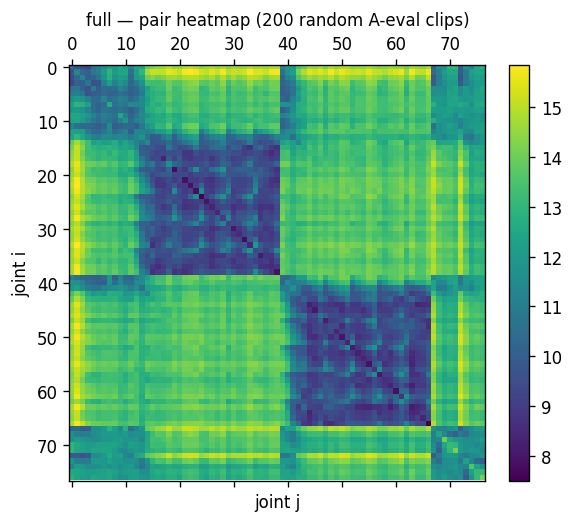

In [9]:
# §1.1 pair heatmap (random 200 A-eval clips)
heatmap = extract_pair_tensor_random(  # #5 random sample
    str(ckpt), test_sets[PRIMARY_EVAL],
    n_clips=200, seed=ENV["seed"],
)
PER_VARIANT_RESULTS[VARIANT]["pair_heatmap"] = heatmap

# Single-variant plot (raw matshow); 4-way grid lives in §7
fig, ax = plt.subplots(figsize=(5, 4.5), facecolor="white")
im = ax.matshow(heatmap, cmap="viridis")
plt.colorbar(im, ax=ax, fraction=0.046)
ax.set_title(f"{VARIANT} — pair heatmap (200 random A-eval clips)", fontsize=10)
ax.set_xlabel("joint j"); ax.set_ylabel("joint i")
show_and_save(fig, RESOURCES / f"figures/01_{VARIANT}_pair_heatmap.png")


### §1.2 per-clip variance PCA

PCA over per-clip embeddings; checks whether `full` collapses to a single
point (input-conditioning failure) or spreads across PC1/PC2.
Uses `pair_norm` embedding (J·J flat per clip).


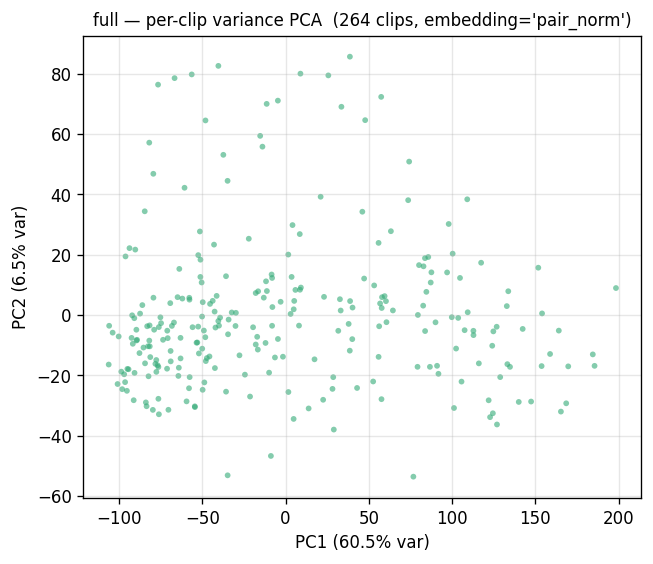

In [10]:
# §1.2 per-clip variance PCA
X, names, labels = extract_pair_embeddings(
    str(ckpt), test_sets[PRIMARY_EVAL],
    embedding="pair_norm",
)
PER_VARIANT_RESULTS[VARIANT]["embedding"] = {"X": X, "names": names, "labels": labels, "kind": "pair_norm"}

from sklearn.decomposition import PCA
pca = PCA(n_components=2, random_state=ENV["seed"]).fit(X)
xy  = pca.transform(X)
v1, v2 = pca.explained_variance_ratio_

fig, ax = plt.subplots(figsize=(6, 5), facecolor="white")
ax.scatter(xy[:, 0], xy[:, 1], s=12, alpha=0.6, c="#3a7", edgecolor="none")
ax.set_xlabel(f"PC1 ({v1*100:.1f}% var)")
ax.set_ylabel(f"PC2 ({v2*100:.1f}% var)")
ax.set_title(f"{VARIANT} — per-clip variance PCA  ({X.shape[0]} clips, embedding='pair_norm')", fontsize=10)
ax.grid(alpha=0.3)
show_and_save(fig, RESOURCES / f"figures/01_{VARIANT}_pca.png")


### §1.3 macro-MPJPE (per-family then macro-averaged)

Per-family MPJPE on A-eval, then equal-weight average over families with n≥10.
This neutralizes the walk-bias in AMASS labeled subset where ~half the clips
are walking.


In [11]:
# §1.3 macro-MPJPE on A-eval
recon = mpjpe_eval(str(ckpt), test_sets[PRIMARY_EVAL])
macro = macro_mpjpe(recon["mpjpe_per_family"], n_per_family=recon["n_per_family"], min_n=10)
PER_VARIANT_RESULTS[VARIANT]["mpjpe"] = {
    "overall":          float(recon["mpjpe_overall"]),
    "macro":            float(macro),
    "per_family":       recon["mpjpe_per_family"],
    "n_per_family":     recon["n_per_family"],
}

import pandas as pd
fam_df = pd.DataFrame({
    "mpjpe_m": pd.Series(recon["mpjpe_per_family"]),
    "n":       pd.Series(recon["n_per_family"]),
}).sort_values("n", ascending=False)
print(f"[{VARIANT}] overall MPJPE = {recon['mpjpe_overall']:.4f} m;   macro (min_n=10) = {macro:.4f} m")
fam_df


[full] overall MPJPE = 0.0085 m;   macro (min_n=10) = 0.0083 m


,mpjpe_m,n
dance,0.009861,93
walk,0.008042,88
locomotion,0.007036,54
manipulate,0.008300,12
sit,0.008274,9
fight,0.008712,3
run,0.008575,2
gesture,0.006219,1
jump,0.007483,1
stretch,0.005749,1


### §1.4 modularity K-sweep (K=3,5,7,10)

KMeans modularity / silhouette / NMI vs ground-truth `action_label` over
K ∈ {3, 5, 7, 10}. Multi-K so the headline metric isn't K-cherry-picked.


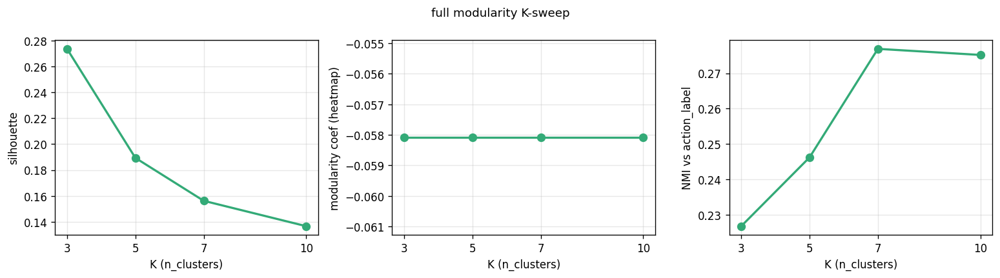

In [12]:
# §1.4 K-sweep over {3, 5, 7, 10}
ks = [3, 5, 7, 10]
ksweep = modularity_k_sweep(  # #3 new wrapper
    str(ckpt), test_sets[PRIMARY_EVAL],
    ks=ks, embedding="pair_norm", seed=ENV["seed"],
)
PER_VARIANT_RESULTS[VARIANT]["k_sweep"] = ksweep

# K-sweep plot (3 metrics × 4 K values, 1 line each)
fig = plot_modularity_k_sweep(ksweep, title=f"{VARIANT} modularity K-sweep")
show_and_save(fig, RESOURCES / f"figures/01_{VARIANT}_k_sweep.png")


### §1.5 `pair_variance` scalar

Single number summarizing per-clip variance — gives §9.2 thesis a numeric
headline. Reported in two flavors:
- `pair_norm`: variance over per-clip pair tensor norms (pair-bearing only)
- `msa_pool`: variance over per-clip MSA-pool embeddings (all 6 variants)


In [13]:
# §1.5 pair_variance scalar (both flavors when applicable)
flavors = ["msa_pool"] + (["pair_norm"] if VARIANT_CAPS[VARIANT]["use_pair"] else [])
pvar = {}
for flv in flavors:
    pvar[flv] = pair_variance_scalar(  # #10 new metric
        str(ckpt), test_sets[PRIMARY_EVAL],
        embedding=flv, seed=ENV["seed"],
    )
PER_VARIANT_RESULTS[VARIANT]["pair_variance"] = pvar
print(f"[{VARIANT}] pair_variance: {pvar}")


[full] using MSA-pool embedding


[full] pair_variance: {'msa_pool': 3.0568754133605838, 'pair_norm': 3.918322253586674}


### §1.6 reconstruction GIFs (4 samples)

4 representative A-eval clips: GT mesh + this variant's reconstruction
(FM 1-step denoise from t=0.95 → un-normalize → FK → LBS → mesh GIF).


  ✓ GT  → gt.gif


  ✓ full           → full.gif


  ✓ GT  → gt.gif


  ✓ full           → full.gif


  ✓ GT  → gt.gif


  ✓ full           → full.gif


  ✓ GT  → gt.gif


  ✓ full           → full.gif
--- 02_5_resources/figures/recon_gifs/full/sample_00_clip_3471/gt.gif ---


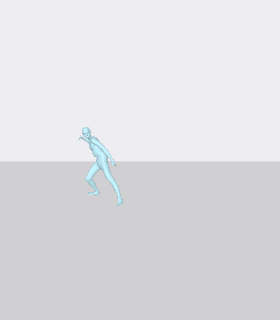

--- 02_5_resources/figures/recon_gifs/full/sample_00_clip_3471/full.gif ---


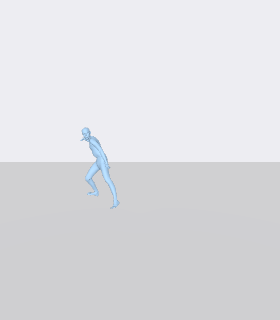

--- 02_5_resources/figures/recon_gifs/full/sample_01_clip_4121/gt.gif ---


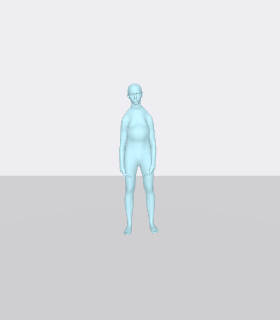

--- 02_5_resources/figures/recon_gifs/full/sample_01_clip_4121/full.gif ---


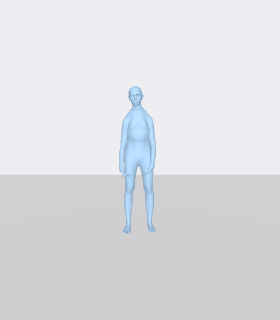

--- 02_5_resources/figures/recon_gifs/full/sample_02_clip_6146/gt.gif ---


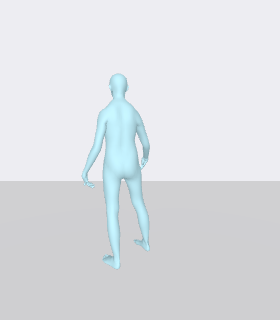

--- 02_5_resources/figures/recon_gifs/full/sample_02_clip_6146/full.gif ---


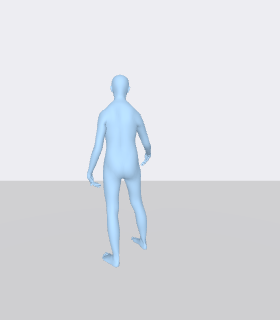

--- 02_5_resources/figures/recon_gifs/full/sample_03_clip_4466/gt.gif ---


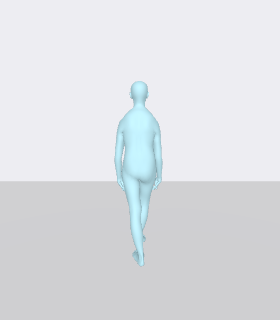

--- 02_5_resources/figures/recon_gifs/full/sample_03_clip_4466/full.gif ---


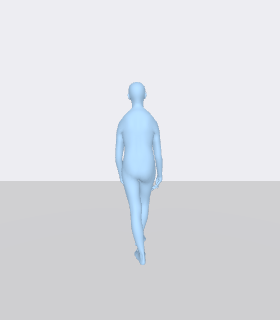

In [14]:
# §1.6 reconstruction GIFs — 4 samples, this variant only
ae = test_sets[PRIMARY_EVAL]
rng = np.random.default_rng(ENV["seed"])
sample_idxs = rng.choice(ae.indices, size=4, replace=False).tolist()

gif_dir = RESOURCES / f"figures/recon_gifs/{VARIANT}"
written_paths = []
for i, clip_idx in enumerate(sample_idxs):
    sub_dir = gif_dir / f"sample_{i:02d}_clip_{int(clip_idx)}"
    paths = render_recon_gif_all(
        int(clip_idx), sub_dir,
        ckpt_paths={VARIANT: ckpt},
        stride=3, fps=10, viewport=(280, 320),
    )
    written_paths.extend(paths)

PER_VARIANT_RESULTS[VARIANT]["gifs"] = [str(p) for p in written_paths]
for p in written_paths:
    print(f"--- {p} ---")
    display(Image(filename=str(p)))


## §2 `opm_only` — pair-bearing

Architecture flags: `use_pair=True`, `use_opm=True`, `use_triangle=False`.

Runs all 6 eval items below before moving to the next variant.


In [15]:
# §2.0 Setup for opm_only
VARIANT = "opm_only"
ckpt = CKPT_ROOT / VARIANT / "latest.pt"
print(f"variant: {VARIANT}  ckpt: {ckpt.name}  caps: {VARIANT_CAPS[VARIANT]}")
PER_VARIANT_RESULTS[VARIANT] = {}   # reset accumulator


variant: opm_only  ckpt: latest.pt  caps: {'use_pair': True, 'use_opm': True, 'use_triangle': False}


### §2.1 pair heatmap (J×J)

Forward 200 random A-eval clips at t=1, hook last block's pair tensor (L2 norm), average.


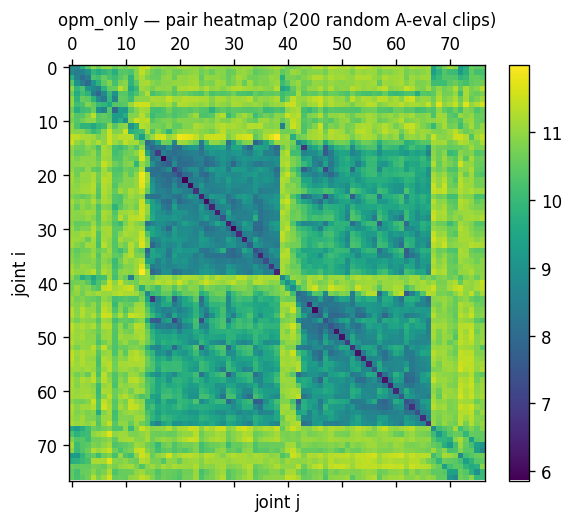

In [16]:
# §2.1 pair heatmap (random 200 A-eval clips)
heatmap = extract_pair_tensor_random(  # #5 random sample
    str(ckpt), test_sets[PRIMARY_EVAL],
    n_clips=200, seed=ENV["seed"],
)
PER_VARIANT_RESULTS[VARIANT]["pair_heatmap"] = heatmap

# Single-variant plot (raw matshow); 4-way grid lives in §7
fig, ax = plt.subplots(figsize=(5, 4.5), facecolor="white")
im = ax.matshow(heatmap, cmap="viridis")
plt.colorbar(im, ax=ax, fraction=0.046)
ax.set_title(f"{VARIANT} — pair heatmap (200 random A-eval clips)", fontsize=10)
ax.set_xlabel("joint j"); ax.set_ylabel("joint i")
show_and_save(fig, RESOURCES / f"figures/02_{VARIANT}_pair_heatmap.png")


### §2.2 per-clip variance PCA

PCA over per-clip embeddings; checks whether `opm_only` collapses to a single
point (input-conditioning failure) or spreads across PC1/PC2.
Uses `pair_norm` embedding (J·J flat per clip).


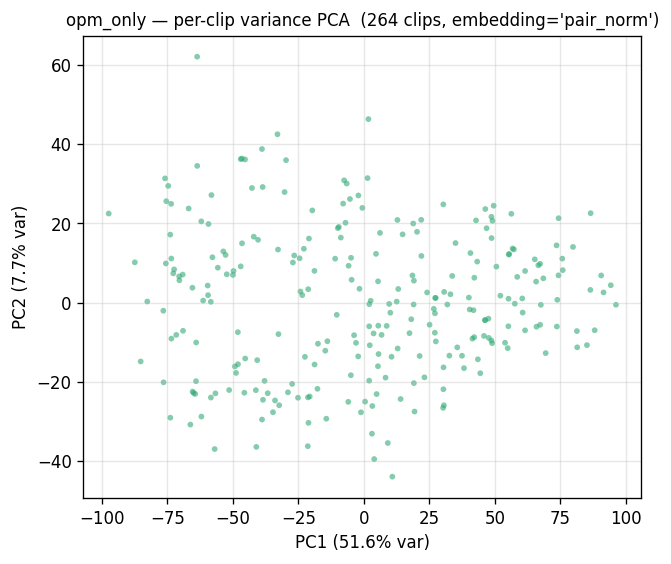

In [17]:
# §2.2 per-clip variance PCA
X, names, labels = extract_pair_embeddings(
    str(ckpt), test_sets[PRIMARY_EVAL],
    embedding="pair_norm",
)
PER_VARIANT_RESULTS[VARIANT]["embedding"] = {"X": X, "names": names, "labels": labels, "kind": "pair_norm"}

from sklearn.decomposition import PCA
pca = PCA(n_components=2, random_state=ENV["seed"]).fit(X)
xy  = pca.transform(X)
v1, v2 = pca.explained_variance_ratio_

fig, ax = plt.subplots(figsize=(6, 5), facecolor="white")
ax.scatter(xy[:, 0], xy[:, 1], s=12, alpha=0.6, c="#3a7", edgecolor="none")
ax.set_xlabel(f"PC1 ({v1*100:.1f}% var)")
ax.set_ylabel(f"PC2 ({v2*100:.1f}% var)")
ax.set_title(f"{VARIANT} — per-clip variance PCA  ({X.shape[0]} clips, embedding='pair_norm')", fontsize=10)
ax.grid(alpha=0.3)
show_and_save(fig, RESOURCES / f"figures/02_{VARIANT}_pca.png")


### §2.3 macro-MPJPE (per-family then macro-averaged)

Per-family MPJPE on A-eval, then equal-weight average over families with n≥10.
This neutralizes the walk-bias in AMASS labeled subset where ~half the clips
are walking.


In [18]:
# §2.3 macro-MPJPE on A-eval
recon = mpjpe_eval(str(ckpt), test_sets[PRIMARY_EVAL])
macro = macro_mpjpe(recon["mpjpe_per_family"], n_per_family=recon["n_per_family"], min_n=10)
PER_VARIANT_RESULTS[VARIANT]["mpjpe"] = {
    "overall":          float(recon["mpjpe_overall"]),
    "macro":            float(macro),
    "per_family":       recon["mpjpe_per_family"],
    "n_per_family":     recon["n_per_family"],
}

import pandas as pd
fam_df = pd.DataFrame({
    "mpjpe_m": pd.Series(recon["mpjpe_per_family"]),
    "n":       pd.Series(recon["n_per_family"]),
}).sort_values("n", ascending=False)
print(f"[{VARIANT}] overall MPJPE = {recon['mpjpe_overall']:.4f} m;   macro (min_n=10) = {macro:.4f} m")
fam_df


[opm_only] overall MPJPE = 0.0087 m;   macro (min_n=10) = 0.0085 m


,mpjpe_m,n
dance,0.010162,93
walk,0.008150,88
locomotion,0.007229,54
manipulate,0.008474,12
sit,0.008309,9
fight,0.009164,3
run,0.008583,2
gesture,0.006447,1
jump,0.007332,1
stretch,0.006050,1


### §2.4 modularity K-sweep (K=3,5,7,10)

KMeans modularity / silhouette / NMI vs ground-truth `action_label` over
K ∈ {3, 5, 7, 10}. Multi-K so the headline metric isn't K-cherry-picked.


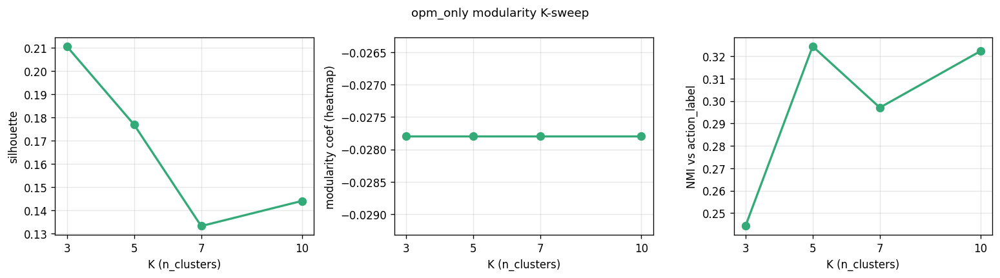

In [19]:
# §2.4 K-sweep over {3, 5, 7, 10}
ks = [3, 5, 7, 10]
ksweep = modularity_k_sweep(  # #3 new wrapper
    str(ckpt), test_sets[PRIMARY_EVAL],
    ks=ks, embedding="pair_norm", seed=ENV["seed"],
)
PER_VARIANT_RESULTS[VARIANT]["k_sweep"] = ksweep

# K-sweep plot (3 metrics × 4 K values, 1 line each)
fig = plot_modularity_k_sweep(ksweep, title=f"{VARIANT} modularity K-sweep")
show_and_save(fig, RESOURCES / f"figures/02_{VARIANT}_k_sweep.png")


### §2.5 `pair_variance` scalar

Single number summarizing per-clip variance — gives §9.2 thesis a numeric
headline. Reported in two flavors:
- `pair_norm`: variance over per-clip pair tensor norms (pair-bearing only)
- `msa_pool`: variance over per-clip MSA-pool embeddings (all 6 variants)


In [20]:
# §2.5 pair_variance scalar (both flavors when applicable)
flavors = ["msa_pool"] + (["pair_norm"] if VARIANT_CAPS[VARIANT]["use_pair"] else [])
pvar = {}
for flv in flavors:
    pvar[flv] = pair_variance_scalar(  # #10 new metric
        str(ckpt), test_sets[PRIMARY_EVAL],
        embedding=flv, seed=ENV["seed"],
    )
PER_VARIANT_RESULTS[VARIANT]["pair_variance"] = pvar
print(f"[{VARIANT}] pair_variance: {pvar}")


[opm_only] using MSA-pool embedding


[opm_only] pair_variance: {'msa_pool': 3.1050625120489403, 'pair_norm': 3.5575338111201575}


### §2.6 reconstruction GIFs (4 samples)

4 representative A-eval clips: GT mesh + this variant's reconstruction
(FM 1-step denoise from t=0.95 → un-normalize → FK → LBS → mesh GIF).


  ✓ GT  → gt.gif


  ✓ opm_only       → opm_only.gif


  ✓ GT  → gt.gif


  ✓ opm_only       → opm_only.gif


  ✓ GT  → gt.gif


  ✓ opm_only       → opm_only.gif


  ✓ GT  → gt.gif


  ✓ opm_only       → opm_only.gif
--- 02_5_resources/figures/recon_gifs/opm_only/sample_00_clip_3471/gt.gif ---


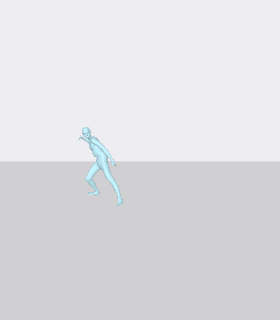

--- 02_5_resources/figures/recon_gifs/opm_only/sample_00_clip_3471/opm_only.gif ---


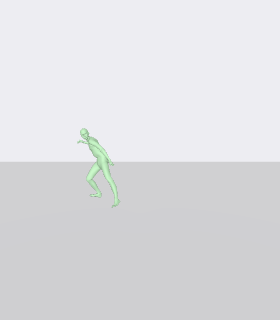

--- 02_5_resources/figures/recon_gifs/opm_only/sample_01_clip_4121/gt.gif ---


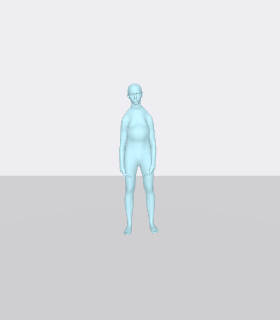

--- 02_5_resources/figures/recon_gifs/opm_only/sample_01_clip_4121/opm_only.gif ---


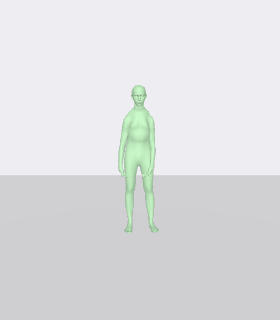

--- 02_5_resources/figures/recon_gifs/opm_only/sample_02_clip_6146/gt.gif ---


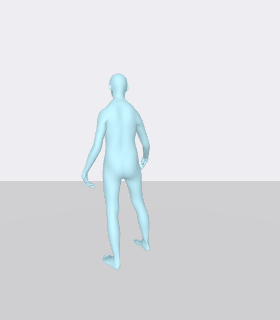

--- 02_5_resources/figures/recon_gifs/opm_only/sample_02_clip_6146/opm_only.gif ---


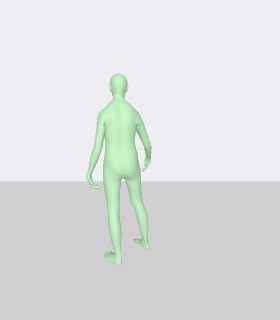

--- 02_5_resources/figures/recon_gifs/opm_only/sample_03_clip_4466/gt.gif ---


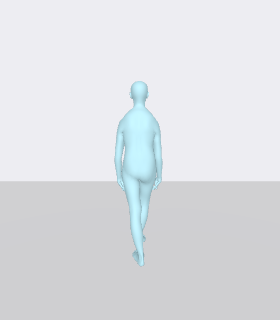

--- 02_5_resources/figures/recon_gifs/opm_only/sample_03_clip_4466/opm_only.gif ---


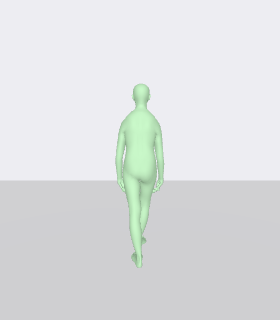

In [21]:
# §2.6 reconstruction GIFs — 4 samples, this variant only
ae = test_sets[PRIMARY_EVAL]
rng = np.random.default_rng(ENV["seed"])
sample_idxs = rng.choice(ae.indices, size=4, replace=False).tolist()

gif_dir = RESOURCES / f"figures/recon_gifs/{VARIANT}"
written_paths = []
for i, clip_idx in enumerate(sample_idxs):
    sub_dir = gif_dir / f"sample_{i:02d}_clip_{int(clip_idx)}"
    paths = render_recon_gif_all(
        int(clip_idx), sub_dir,
        ckpt_paths={VARIANT: ckpt},
        stride=3, fps=10, viewport=(280, 320),
    )
    written_paths.extend(paths)

PER_VARIANT_RESULTS[VARIANT]["gifs"] = [str(p) for p in written_paths]
for p in written_paths:
    print(f"--- {p} ---")
    display(Image(filename=str(p)))


## §3 `triangle_only` — pair-bearing

Architecture flags: `use_pair=True`, `use_opm=False`, `use_triangle=True`.

Runs all 6 eval items below before moving to the next variant.


In [22]:
# §3.0 Setup for triangle_only
VARIANT = "triangle_only"
ckpt = CKPT_ROOT / VARIANT / "latest.pt"
print(f"variant: {VARIANT}  ckpt: {ckpt.name}  caps: {VARIANT_CAPS[VARIANT]}")
PER_VARIANT_RESULTS[VARIANT] = {}   # reset accumulator


variant: triangle_only  ckpt: latest.pt  caps: {'use_pair': True, 'use_opm': False, 'use_triangle': True}


### §3.1 pair heatmap (J×J)

Forward 200 random A-eval clips at t=1, hook last block's pair tensor (L2 norm), average.


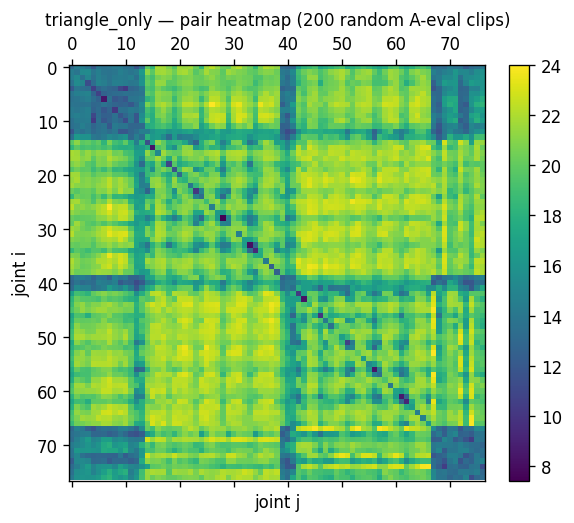

In [23]:
# §3.1 pair heatmap (random 200 A-eval clips)
heatmap = extract_pair_tensor_random(  # #5 random sample
    str(ckpt), test_sets[PRIMARY_EVAL],
    n_clips=200, seed=ENV["seed"],
)
PER_VARIANT_RESULTS[VARIANT]["pair_heatmap"] = heatmap

# Single-variant plot (raw matshow); 4-way grid lives in §7
fig, ax = plt.subplots(figsize=(5, 4.5), facecolor="white")
im = ax.matshow(heatmap, cmap="viridis")
plt.colorbar(im, ax=ax, fraction=0.046)
ax.set_title(f"{VARIANT} — pair heatmap (200 random A-eval clips)", fontsize=10)
ax.set_xlabel("joint j"); ax.set_ylabel("joint i")
show_and_save(fig, RESOURCES / f"figures/03_{VARIANT}_pair_heatmap.png")


### §3.2 per-clip variance PCA

PCA over per-clip embeddings; checks whether `triangle_only` collapses to a single
point (input-conditioning failure) or spreads across PC1/PC2.
Uses `pair_norm` embedding (J·J flat per clip).


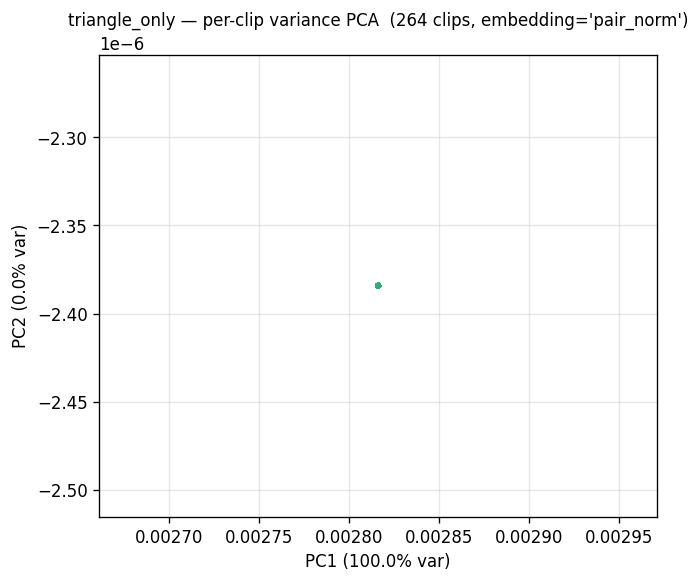

In [24]:
# §3.2 per-clip variance PCA
X, names, labels = extract_pair_embeddings(
    str(ckpt), test_sets[PRIMARY_EVAL],
    embedding="pair_norm",
)
PER_VARIANT_RESULTS[VARIANT]["embedding"] = {"X": X, "names": names, "labels": labels, "kind": "pair_norm"}

from sklearn.decomposition import PCA
pca = PCA(n_components=2, random_state=ENV["seed"]).fit(X)
xy  = pca.transform(X)
v1, v2 = pca.explained_variance_ratio_

fig, ax = plt.subplots(figsize=(6, 5), facecolor="white")
ax.scatter(xy[:, 0], xy[:, 1], s=12, alpha=0.6, c="#3a7", edgecolor="none")
ax.set_xlabel(f"PC1 ({v1*100:.1f}% var)")
ax.set_ylabel(f"PC2 ({v2*100:.1f}% var)")
ax.set_title(f"{VARIANT} — per-clip variance PCA  ({X.shape[0]} clips, embedding='pair_norm')", fontsize=10)
ax.grid(alpha=0.3)
show_and_save(fig, RESOURCES / f"figures/03_{VARIANT}_pca.png")


### §3.3 macro-MPJPE (per-family then macro-averaged)

Per-family MPJPE on A-eval, then equal-weight average over families with n≥10.
This neutralizes the walk-bias in AMASS labeled subset where ~half the clips
are walking.


In [25]:
# §3.3 macro-MPJPE on A-eval
recon = mpjpe_eval(str(ckpt), test_sets[PRIMARY_EVAL])
macro = macro_mpjpe(recon["mpjpe_per_family"], n_per_family=recon["n_per_family"], min_n=10)
PER_VARIANT_RESULTS[VARIANT]["mpjpe"] = {
    "overall":          float(recon["mpjpe_overall"]),
    "macro":            float(macro),
    "per_family":       recon["mpjpe_per_family"],
    "n_per_family":     recon["n_per_family"],
}

import pandas as pd
fam_df = pd.DataFrame({
    "mpjpe_m": pd.Series(recon["mpjpe_per_family"]),
    "n":       pd.Series(recon["n_per_family"]),
}).sort_values("n", ascending=False)
print(f"[{VARIANT}] overall MPJPE = {recon['mpjpe_overall']:.4f} m;   macro (min_n=10) = {macro:.4f} m")
fam_df


[triangle_only] overall MPJPE = 0.0096 m;   macro (min_n=10) = 0.0093 m


,mpjpe_m,n
dance,0.010978,93
walk,0.009144,88
locomotion,0.008013,54
manipulate,0.009158,12
sit,0.009186,9
fight,0.009815,3
run,0.009583,2
gesture,0.007240,1
jump,0.008494,1
stretch,0.006532,1


### §3.4 modularity K-sweep (K=3,5,7,10)

KMeans modularity / silhouette / NMI vs ground-truth `action_label` over
K ∈ {3, 5, 7, 10}. Multi-K so the headline metric isn't K-cherry-picked.


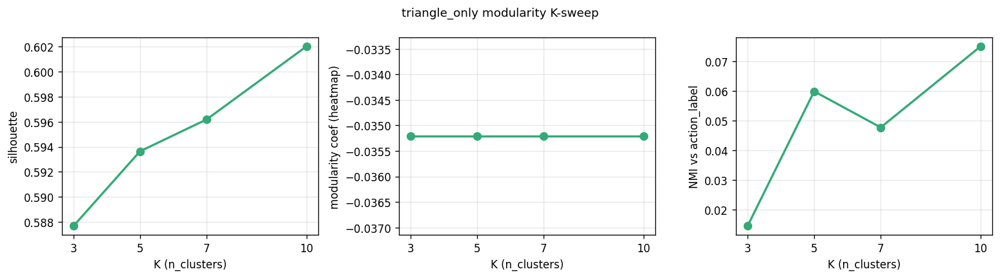

In [26]:
# §3.4 K-sweep over {3, 5, 7, 10}
ks = [3, 5, 7, 10]
ksweep = modularity_k_sweep(  # #3 new wrapper
    str(ckpt), test_sets[PRIMARY_EVAL],
    ks=ks, embedding="pair_norm", seed=ENV["seed"],
)
PER_VARIANT_RESULTS[VARIANT]["k_sweep"] = ksweep

# K-sweep plot (3 metrics × 4 K values, 1 line each)
fig = plot_modularity_k_sweep(ksweep, title=f"{VARIANT} modularity K-sweep")
show_and_save(fig, RESOURCES / f"figures/03_{VARIANT}_k_sweep.png")


### §3.5 `pair_variance` scalar

Single number summarizing per-clip variance — gives §9.2 thesis a numeric
headline. Reported in two flavors:
- `pair_norm`: variance over per-clip pair tensor norms (pair-bearing only)
- `msa_pool`: variance over per-clip MSA-pool embeddings (all 6 variants)


In [27]:
# §3.5 pair_variance scalar (both flavors when applicable)
flavors = ["msa_pool"] + (["pair_norm"] if VARIANT_CAPS[VARIANT]["use_pair"] else [])
pvar = {}
for flv in flavors:
    pvar[flv] = pair_variance_scalar(  # #10 new metric
        str(ckpt), test_sets[PRIMARY_EVAL],
        embedding=flv, seed=ENV["seed"],
    )
PER_VARIANT_RESULTS[VARIANT]["pair_variance"] = pvar
print(f"[{VARIANT}] pair_variance: {pvar}")


[triangle_only] using MSA-pool embedding


[triangle_only] pair_variance: {'msa_pool': 3.0217571417439655, 'pair_norm': -5.3133939257339575}


### §3.6 reconstruction GIFs (4 samples)

4 representative A-eval clips: GT mesh + this variant's reconstruction
(FM 1-step denoise from t=0.95 → un-normalize → FK → LBS → mesh GIF).


  ✓ GT  → gt.gif


  ✓ triangle_only  → triangle_only.gif


  ✓ GT  → gt.gif


  ✓ triangle_only  → triangle_only.gif


  ✓ GT  → gt.gif


  ✓ triangle_only  → triangle_only.gif


  ✓ GT  → gt.gif


  ✓ triangle_only  → triangle_only.gif
--- 02_5_resources/figures/recon_gifs/triangle_only/sample_00_clip_3471/gt.gif ---


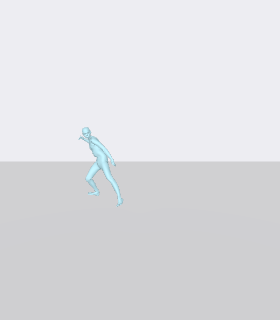

--- 02_5_resources/figures/recon_gifs/triangle_only/sample_00_clip_3471/triangle_only.gif ---


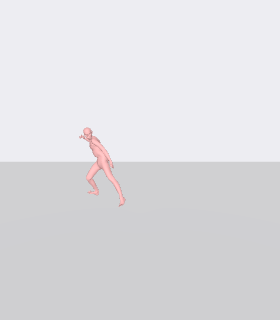

--- 02_5_resources/figures/recon_gifs/triangle_only/sample_01_clip_4121/gt.gif ---


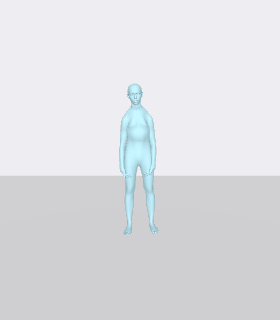

--- 02_5_resources/figures/recon_gifs/triangle_only/sample_01_clip_4121/triangle_only.gif ---


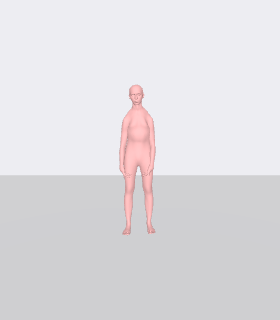

--- 02_5_resources/figures/recon_gifs/triangle_only/sample_02_clip_6146/gt.gif ---


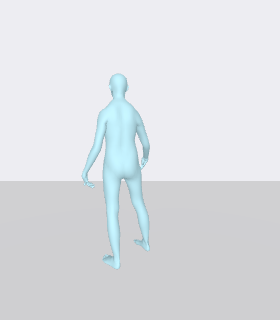

--- 02_5_resources/figures/recon_gifs/triangle_only/sample_02_clip_6146/triangle_only.gif ---


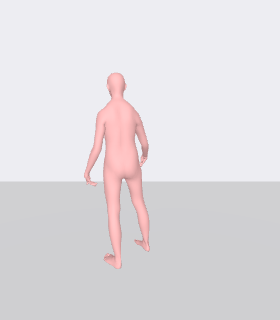

--- 02_5_resources/figures/recon_gifs/triangle_only/sample_03_clip_4466/gt.gif ---


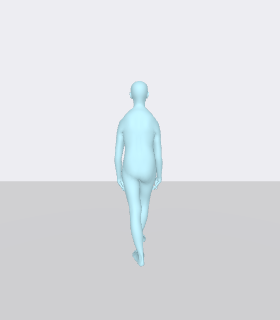

--- 02_5_resources/figures/recon_gifs/triangle_only/sample_03_clip_4466/triangle_only.gif ---


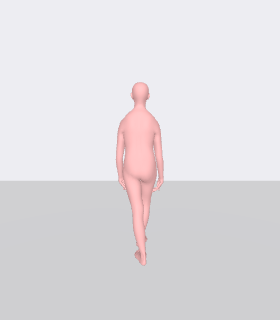

In [28]:
# §3.6 reconstruction GIFs — 4 samples, this variant only
ae = test_sets[PRIMARY_EVAL]
rng = np.random.default_rng(ENV["seed"])
sample_idxs = rng.choice(ae.indices, size=4, replace=False).tolist()

gif_dir = RESOURCES / f"figures/recon_gifs/{VARIANT}"
written_paths = []
for i, clip_idx in enumerate(sample_idxs):
    sub_dir = gif_dir / f"sample_{i:02d}_clip_{int(clip_idx)}"
    paths = render_recon_gif_all(
        int(clip_idx), sub_dir,
        ckpt_paths={VARIANT: ckpt},
        stride=3, fps=10, viewport=(280, 320),
    )
    written_paths.extend(paths)

PER_VARIANT_RESULTS[VARIANT]["gifs"] = [str(p) for p in written_paths]
for p in written_paths:
    print(f"--- {p} ---")
    display(Image(filename=str(p)))


## §4 `pair_static` — pair-bearing

Architecture flags: `use_pair=True`, `use_opm=False`, `use_triangle=False`.

Runs all 6 eval items below before moving to the next variant.


In [29]:
# §4.0 Setup for pair_static
VARIANT = "pair_static"
ckpt = CKPT_ROOT / VARIANT / "latest.pt"
print(f"variant: {VARIANT}  ckpt: {ckpt.name}  caps: {VARIANT_CAPS[VARIANT]}")
PER_VARIANT_RESULTS[VARIANT] = {}   # reset accumulator


variant: pair_static  ckpt: latest.pt  caps: {'use_pair': True, 'use_opm': False, 'use_triangle': False}


### §4.1 pair heatmap (J×J)

Forward 200 random A-eval clips at t=1, hook last block's pair tensor (L2 norm), average.


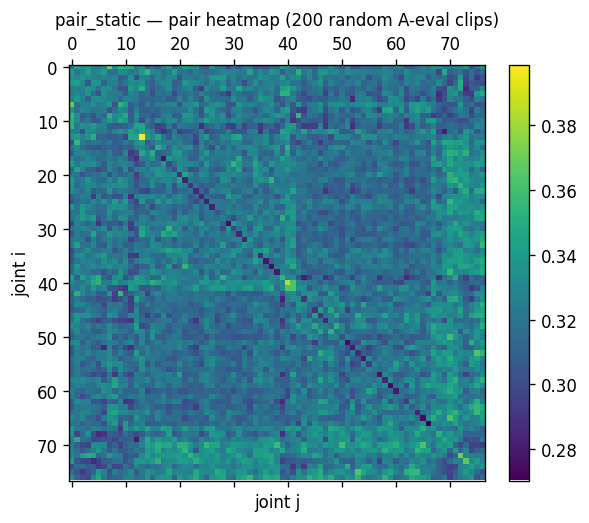

In [30]:
# §4.1 pair heatmap (random 200 A-eval clips)
heatmap = extract_pair_tensor_random(  # #5 random sample
    str(ckpt), test_sets[PRIMARY_EVAL],
    n_clips=200, seed=ENV["seed"],
)
PER_VARIANT_RESULTS[VARIANT]["pair_heatmap"] = heatmap

# Single-variant plot (raw matshow); 4-way grid lives in §7
fig, ax = plt.subplots(figsize=(5, 4.5), facecolor="white")
im = ax.matshow(heatmap, cmap="viridis")
plt.colorbar(im, ax=ax, fraction=0.046)
ax.set_title(f"{VARIANT} — pair heatmap (200 random A-eval clips)", fontsize=10)
ax.set_xlabel("joint j"); ax.set_ylabel("joint i")
show_and_save(fig, RESOURCES / f"figures/04_{VARIANT}_pair_heatmap.png")


### §4.2 per-clip variance PCA

PCA over per-clip embeddings; checks whether `pair_static` collapses to a single
point (input-conditioning failure) or spreads across PC1/PC2.
Uses `pair_norm` embedding (J·J flat per clip).


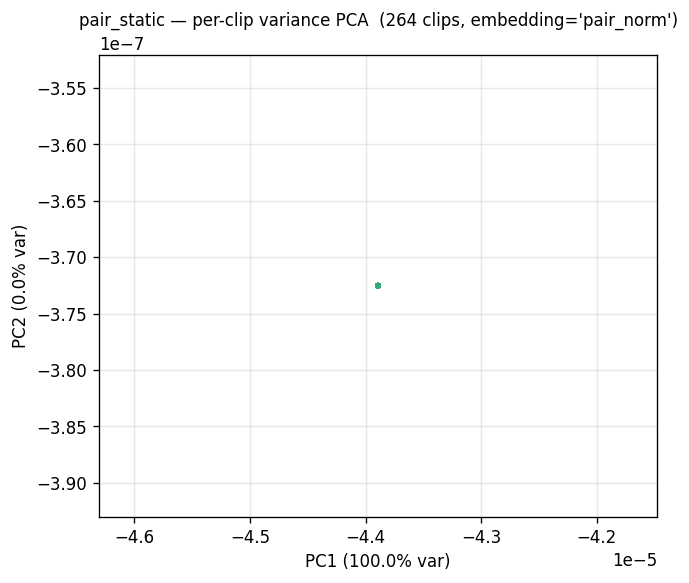

In [31]:
# §4.2 per-clip variance PCA
X, names, labels = extract_pair_embeddings(
    str(ckpt), test_sets[PRIMARY_EVAL],
    embedding="pair_norm",
)
PER_VARIANT_RESULTS[VARIANT]["embedding"] = {"X": X, "names": names, "labels": labels, "kind": "pair_norm"}

from sklearn.decomposition import PCA
pca = PCA(n_components=2, random_state=ENV["seed"]).fit(X)
xy  = pca.transform(X)
v1, v2 = pca.explained_variance_ratio_

fig, ax = plt.subplots(figsize=(6, 5), facecolor="white")
ax.scatter(xy[:, 0], xy[:, 1], s=12, alpha=0.6, c="#3a7", edgecolor="none")
ax.set_xlabel(f"PC1 ({v1*100:.1f}% var)")
ax.set_ylabel(f"PC2 ({v2*100:.1f}% var)")
ax.set_title(f"{VARIANT} — per-clip variance PCA  ({X.shape[0]} clips, embedding='pair_norm')", fontsize=10)
ax.grid(alpha=0.3)
show_and_save(fig, RESOURCES / f"figures/04_{VARIANT}_pca.png")


### §4.3 macro-MPJPE (per-family then macro-averaged)

Per-family MPJPE on A-eval, then equal-weight average over families with n≥10.
This neutralizes the walk-bias in AMASS labeled subset where ~half the clips
are walking.


In [32]:
# §4.3 macro-MPJPE on A-eval
recon = mpjpe_eval(str(ckpt), test_sets[PRIMARY_EVAL])
macro = macro_mpjpe(recon["mpjpe_per_family"], n_per_family=recon["n_per_family"], min_n=10)
PER_VARIANT_RESULTS[VARIANT]["mpjpe"] = {
    "overall":          float(recon["mpjpe_overall"]),
    "macro":            float(macro),
    "per_family":       recon["mpjpe_per_family"],
    "n_per_family":     recon["n_per_family"],
}

import pandas as pd
fam_df = pd.DataFrame({
    "mpjpe_m": pd.Series(recon["mpjpe_per_family"]),
    "n":       pd.Series(recon["n_per_family"]),
}).sort_values("n", ascending=False)
print(f"[{VARIANT}] overall MPJPE = {recon['mpjpe_overall']:.4f} m;   macro (min_n=10) = {macro:.4f} m")
fam_df


[pair_static] overall MPJPE = 0.0086 m;   macro (min_n=10) = 0.0084 m


,mpjpe_m,n
dance,0.009961,93
walk,0.008155,88
locomotion,0.007244,54
manipulate,0.008314,12
sit,0.008496,9
fight,0.009049,3
run,0.008720,2
gesture,0.007080,1
jump,0.007091,1
stretch,0.005969,1


### §4.4 modularity K-sweep (K=3,5,7,10)

KMeans modularity / silhouette / NMI vs ground-truth `action_label` over
K ∈ {3, 5, 7, 10}. Multi-K so the headline metric isn't K-cherry-picked.


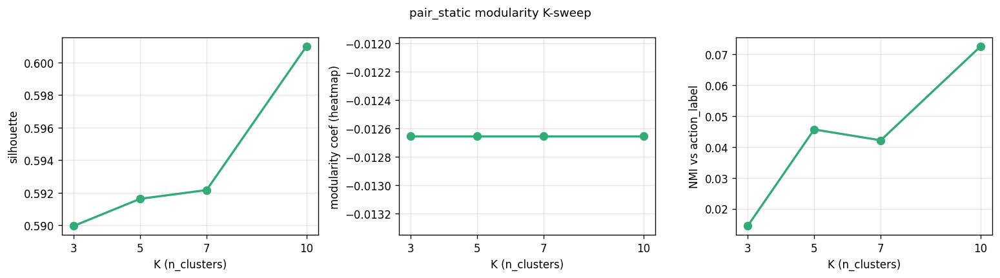

In [33]:
# §4.4 K-sweep over {3, 5, 7, 10}
ks = [3, 5, 7, 10]
ksweep = modularity_k_sweep(  # #3 new wrapper
    str(ckpt), test_sets[PRIMARY_EVAL],
    ks=ks, embedding="pair_norm", seed=ENV["seed"],
)
PER_VARIANT_RESULTS[VARIANT]["k_sweep"] = ksweep

# K-sweep plot (3 metrics × 4 K values, 1 line each)
fig = plot_modularity_k_sweep(ksweep, title=f"{VARIANT} modularity K-sweep")
show_and_save(fig, RESOURCES / f"figures/04_{VARIANT}_k_sweep.png")


### §4.5 `pair_variance` scalar

Single number summarizing per-clip variance — gives §9.2 thesis a numeric
headline. Reported in two flavors:
- `pair_norm`: variance over per-clip pair tensor norms (pair-bearing only)
- `msa_pool`: variance over per-clip MSA-pool embeddings (all 6 variants)


In [34]:
# §4.5 pair_variance scalar (both flavors when applicable)
flavors = ["msa_pool"] + (["pair_norm"] if VARIANT_CAPS[VARIANT]["use_pair"] else [])
pvar = {}
for flv in flavors:
    pvar[flv] = pair_variance_scalar(  # #10 new metric
        str(ckpt), test_sets[PRIMARY_EVAL],
        embedding=flv, seed=ENV["seed"],
    )
PER_VARIANT_RESULTS[VARIANT]["pair_variance"] = pvar
print(f"[{VARIANT}] pair_variance: {pvar}")


[pair_static] using MSA-pool embedding


[pair_static] pair_variance: {'msa_pool': 3.147769325422533, 'pair_norm': -8.835343979367211}


### §4.6 reconstruction GIFs (4 samples)

4 representative A-eval clips: GT mesh + this variant's reconstruction
(FM 1-step denoise from t=0.95 → un-normalize → FK → LBS → mesh GIF).


  ✓ GT  → gt.gif


  ✓ pair_static    → pair_static.gif


  ✓ GT  → gt.gif


  ✓ pair_static    → pair_static.gif


  ✓ GT  → gt.gif


  ✓ pair_static    → pair_static.gif


  ✓ GT  → gt.gif


  ✓ pair_static    → pair_static.gif
--- 02_5_resources/figures/recon_gifs/pair_static/sample_00_clip_3471/gt.gif ---


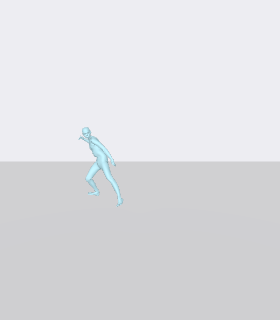

--- 02_5_resources/figures/recon_gifs/pair_static/sample_00_clip_3471/pair_static.gif ---


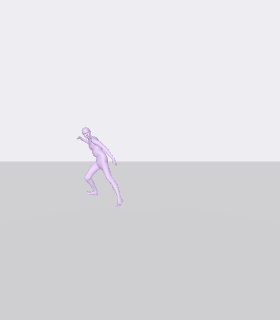

--- 02_5_resources/figures/recon_gifs/pair_static/sample_01_clip_4121/gt.gif ---


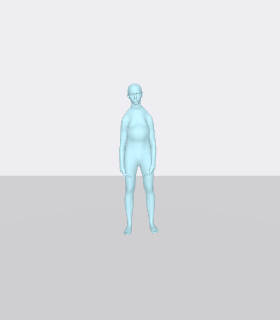

--- 02_5_resources/figures/recon_gifs/pair_static/sample_01_clip_4121/pair_static.gif ---


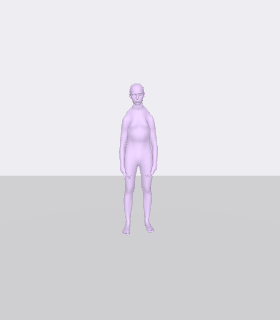

--- 02_5_resources/figures/recon_gifs/pair_static/sample_02_clip_6146/gt.gif ---


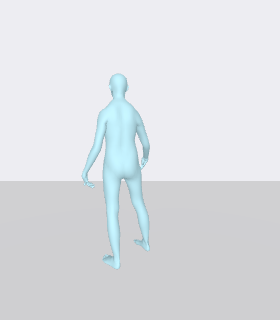

--- 02_5_resources/figures/recon_gifs/pair_static/sample_02_clip_6146/pair_static.gif ---


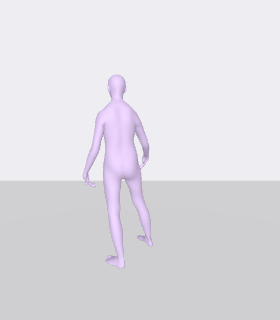

--- 02_5_resources/figures/recon_gifs/pair_static/sample_03_clip_4466/gt.gif ---


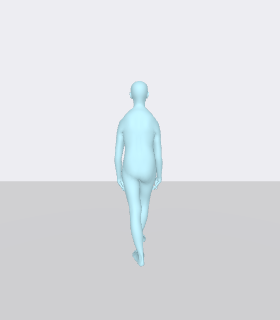

--- 02_5_resources/figures/recon_gifs/pair_static/sample_03_clip_4466/pair_static.gif ---


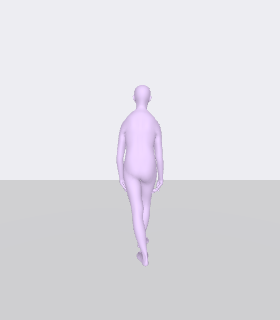

In [35]:
# §4.6 reconstruction GIFs — 4 samples, this variant only
ae = test_sets[PRIMARY_EVAL]
rng = np.random.default_rng(ENV["seed"])
sample_idxs = rng.choice(ae.indices, size=4, replace=False).tolist()

gif_dir = RESOURCES / f"figures/recon_gifs/{VARIANT}"
written_paths = []
for i, clip_idx in enumerate(sample_idxs):
    sub_dir = gif_dir / f"sample_{i:02d}_clip_{int(clip_idx)}"
    paths = render_recon_gif_all(
        int(clip_idx), sub_dir,
        ckpt_paths={VARIANT: ckpt},
        stride=3, fps=10, viewport=(280, 320),
    )
    written_paths.extend(paths)

PER_VARIANT_RESULTS[VARIANT]["gifs"] = [str(p) for p in written_paths]
for p in written_paths:
    print(f"--- {p} ---")
    display(Image(filename=str(p)))


## §5 `axial_only` — MSA-only (no pair tensor)

Architecture flags: `use_pair=False`, `use_opm=False`, `use_triangle=False`.

Runs all 6 eval items below before moving to the next variant.


In [36]:
# §5.0 Setup for axial_only
VARIANT = "axial_only"
ckpt = CKPT_ROOT / VARIANT / "latest.pt"
print(f"variant: {VARIANT}  ckpt: {ckpt.name}  caps: {VARIANT_CAPS[VARIANT]}")
PER_VARIANT_RESULTS[VARIANT] = {}   # reset accumulator


variant: axial_only  ckpt: latest.pt  caps: {'use_pair': False, 'use_opm': False, 'use_triangle': False}


### §5.1 pair heatmap (J×J)

**N/A** — `axial_only` has no pair tensor (use_pair=False). Cell skipped.


In [37]:
# §5.1 SKIPPED — axial_only has no pair tensor
PER_VARIANT_RESULTS[VARIANT]["pair_heatmap"] = None
print(f"[{VARIANT}] pair heatmap N/A (no pair tensor)")


[axial_only] pair heatmap N/A (no pair tensor)


### §5.2 per-clip variance PCA

PCA over per-clip embeddings; checks whether `axial_only` collapses to a single
point (input-conditioning failure) or spreads across PC1/PC2.
Uses `msa_pool` embedding (J·H flat per clip) since no pair tensor.


[axial_only] using MSA-pool embedding


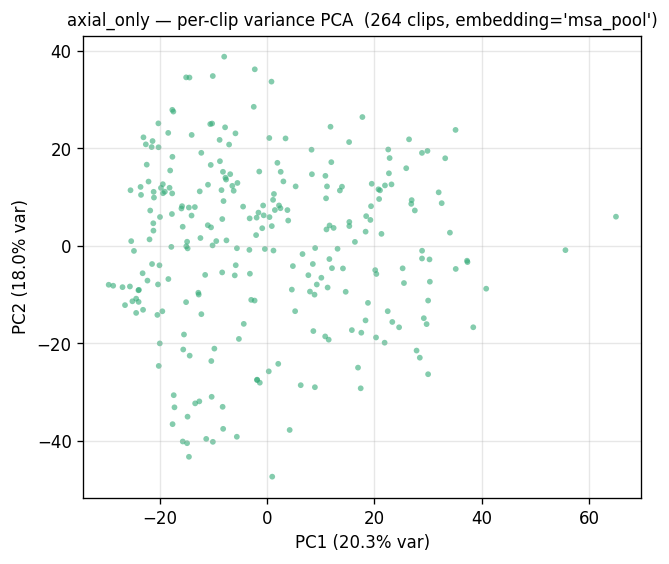

In [38]:
# §5.2 per-clip variance PCA
X, names, labels = extract_pair_embeddings(
    str(ckpt), test_sets[PRIMARY_EVAL],
    embedding="msa_pool",
)
PER_VARIANT_RESULTS[VARIANT]["embedding"] = {"X": X, "names": names, "labels": labels, "kind": "msa_pool"}

from sklearn.decomposition import PCA
pca = PCA(n_components=2, random_state=ENV["seed"]).fit(X)
xy  = pca.transform(X)
v1, v2 = pca.explained_variance_ratio_

fig, ax = plt.subplots(figsize=(6, 5), facecolor="white")
ax.scatter(xy[:, 0], xy[:, 1], s=12, alpha=0.6, c="#3a7", edgecolor="none")
ax.set_xlabel(f"PC1 ({v1*100:.1f}% var)")
ax.set_ylabel(f"PC2 ({v2*100:.1f}% var)")
ax.set_title(f"{VARIANT} — per-clip variance PCA  ({X.shape[0]} clips, embedding='msa_pool')", fontsize=10)
ax.grid(alpha=0.3)
show_and_save(fig, RESOURCES / f"figures/05_{VARIANT}_pca.png")


### §5.3 macro-MPJPE (per-family then macro-averaged)

Per-family MPJPE on A-eval, then equal-weight average over families with n≥10.
This neutralizes the walk-bias in AMASS labeled subset where ~half the clips
are walking.


In [39]:
# §5.3 macro-MPJPE on A-eval
recon = mpjpe_eval(str(ckpt), test_sets[PRIMARY_EVAL])
macro = macro_mpjpe(recon["mpjpe_per_family"], n_per_family=recon["n_per_family"], min_n=10)
PER_VARIANT_RESULTS[VARIANT]["mpjpe"] = {
    "overall":          float(recon["mpjpe_overall"]),
    "macro":            float(macro),
    "per_family":       recon["mpjpe_per_family"],
    "n_per_family":     recon["n_per_family"],
}

import pandas as pd
fam_df = pd.DataFrame({
    "mpjpe_m": pd.Series(recon["mpjpe_per_family"]),
    "n":       pd.Series(recon["n_per_family"]),
}).sort_values("n", ascending=False)
print(f"[{VARIANT}] overall MPJPE = {recon['mpjpe_overall']:.4f} m;   macro (min_n=10) = {macro:.4f} m")
fam_df


[axial_only] overall MPJPE = 0.0089 m;   macro (min_n=10) = 0.0087 m


,mpjpe_m,n
dance,0.010320,93
walk,0.008325,88
locomotion,0.007418,54
manipulate,0.008815,12
sit,0.008637,9
fight,0.009112,3
run,0.009234,2
gesture,0.006740,1
jump,0.007226,1
stretch,0.005726,1


### §5.4 modularity K-sweep (K=3,5,7,10)

KMeans modularity / silhouette / NMI vs ground-truth `action_label` over
K ∈ {3, 5, 7, 10}. Multi-K so the headline metric isn't K-cherry-picked.


[axial_only] using MSA-pool embedding


[axial_only] no pair tensor; returning None


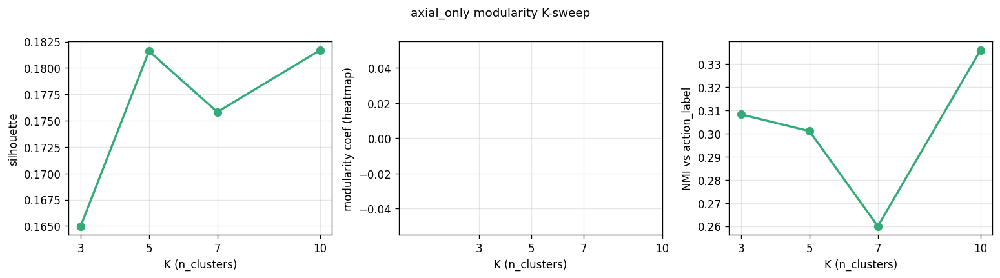

In [40]:
# §5.4 K-sweep over {3, 5, 7, 10}
ks = [3, 5, 7, 10]
ksweep = modularity_k_sweep(  # #3 new wrapper
    str(ckpt), test_sets[PRIMARY_EVAL],
    ks=ks, embedding="msa_pool", seed=ENV["seed"],
)
PER_VARIANT_RESULTS[VARIANT]["k_sweep"] = ksweep

# K-sweep plot (3 metrics × 4 K values, 1 line each)
fig = plot_modularity_k_sweep(ksweep, title=f"{VARIANT} modularity K-sweep")
show_and_save(fig, RESOURCES / f"figures/05_{VARIANT}_k_sweep.png")


### §5.5 `pair_variance` scalar

Single number summarizing per-clip variance — gives §9.2 thesis a numeric
headline. Reported in two flavors:
- `pair_norm`: variance over per-clip pair tensor norms (pair-bearing only)
- `msa_pool`: variance over per-clip MSA-pool embeddings (all 6 variants)


In [41]:
# §5.5 pair_variance scalar (both flavors when applicable)
flavors = ["msa_pool"] + (["pair_norm"] if VARIANT_CAPS[VARIANT]["use_pair"] else [])
pvar = {}
for flv in flavors:
    pvar[flv] = pair_variance_scalar(  # #10 new metric
        str(ckpt), test_sets[PRIMARY_EVAL],
        embedding=flv, seed=ENV["seed"],
    )
PER_VARIANT_RESULTS[VARIANT]["pair_variance"] = pvar
print(f"[{VARIANT}] pair_variance: {pvar}")


[axial_only] using MSA-pool embedding


[axial_only] pair_variance: {'msa_pool': 3.1361661154991323}


### §5.6 reconstruction GIFs (4 samples)

4 representative A-eval clips: GT mesh + this variant's reconstruction
(FM 1-step denoise from t=0.95 → un-normalize → FK → LBS → mesh GIF).


  ✓ GT  → gt.gif


  ✓ axial_only     → axial_only.gif


  ✓ GT  → gt.gif


  ✓ axial_only     → axial_only.gif


  ✓ GT  → gt.gif


  ✓ axial_only     → axial_only.gif


  ✓ GT  → gt.gif


  ✓ axial_only     → axial_only.gif
--- 02_5_resources/figures/recon_gifs/axial_only/sample_00_clip_3471/gt.gif ---


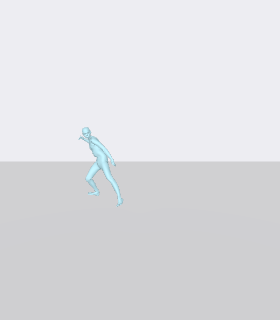

--- 02_5_resources/figures/recon_gifs/axial_only/sample_00_clip_3471/axial_only.gif ---


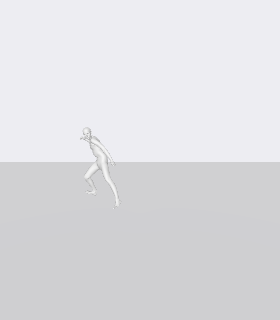

--- 02_5_resources/figures/recon_gifs/axial_only/sample_01_clip_4121/gt.gif ---


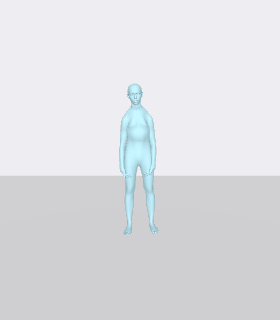

--- 02_5_resources/figures/recon_gifs/axial_only/sample_01_clip_4121/axial_only.gif ---


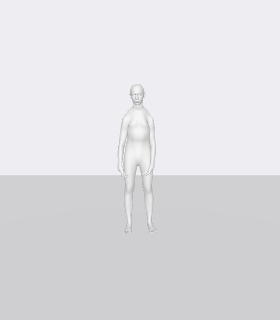

--- 02_5_resources/figures/recon_gifs/axial_only/sample_02_clip_6146/gt.gif ---


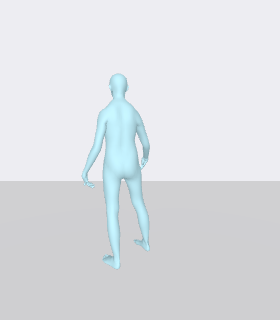

--- 02_5_resources/figures/recon_gifs/axial_only/sample_02_clip_6146/axial_only.gif ---


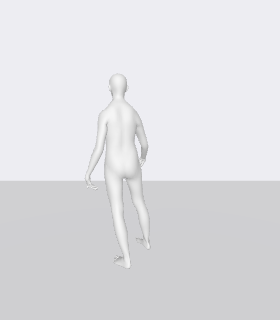

--- 02_5_resources/figures/recon_gifs/axial_only/sample_03_clip_4466/gt.gif ---


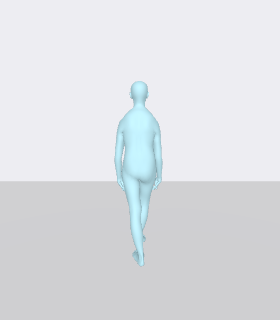

--- 02_5_resources/figures/recon_gifs/axial_only/sample_03_clip_4466/axial_only.gif ---


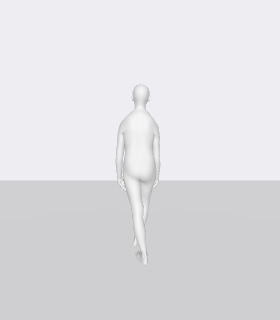

In [42]:
# §5.6 reconstruction GIFs — 4 samples, this variant only
ae = test_sets[PRIMARY_EVAL]
rng = np.random.default_rng(ENV["seed"])
sample_idxs = rng.choice(ae.indices, size=4, replace=False).tolist()

gif_dir = RESOURCES / f"figures/recon_gifs/{VARIANT}"
written_paths = []
for i, clip_idx in enumerate(sample_idxs):
    sub_dir = gif_dir / f"sample_{i:02d}_clip_{int(clip_idx)}"
    paths = render_recon_gif_all(
        int(clip_idx), sub_dir,
        ckpt_paths={VARIANT: ckpt},
        stride=3, fps=10, viewport=(280, 320),
    )
    written_paths.extend(paths)

PER_VARIANT_RESULTS[VARIANT]["gifs"] = [str(p) for p in written_paths]
for p in written_paths:
    print(f"--- {p} ---")
    display(Image(filename=str(p)))


## §6 `baseline` — MSA-only (no pair tensor)

Architecture flags: `use_pair=False`, `use_opm=False`, `use_triangle=False`.

Runs all 6 eval items below before moving to the next variant.


In [43]:
# §6.0 Setup for baseline
VARIANT = "baseline"
ckpt = CKPT_ROOT / VARIANT / "latest.pt"
print(f"variant: {VARIANT}  ckpt: {ckpt.name}  caps: {VARIANT_CAPS[VARIANT]}")
PER_VARIANT_RESULTS[VARIANT] = {}   # reset accumulator


variant: baseline  ckpt: latest.pt  caps: {'use_pair': False, 'use_opm': False, 'use_triangle': False}


### §6.1 pair heatmap (J×J)

**N/A** — `baseline` has no pair tensor (use_pair=False). Cell skipped.


In [44]:
# §6.1 SKIPPED — baseline has no pair tensor
PER_VARIANT_RESULTS[VARIANT]["pair_heatmap"] = None
print(f"[{VARIANT}] pair heatmap N/A (no pair tensor)")


[baseline] pair heatmap N/A (no pair tensor)


### §6.2 per-clip variance PCA

PCA over per-clip embeddings; checks whether `baseline` collapses to a single
point (input-conditioning failure) or spreads across PC1/PC2.
Uses `msa_pool` embedding (J·H flat per clip) since no pair tensor.


[baseline] using MSA-pool embedding


/home/arenalabs/miniconda3/envs/rot/lib/python3.12/site-packages/torch/nn/modules/transformer.py:392: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  warnings.warn(


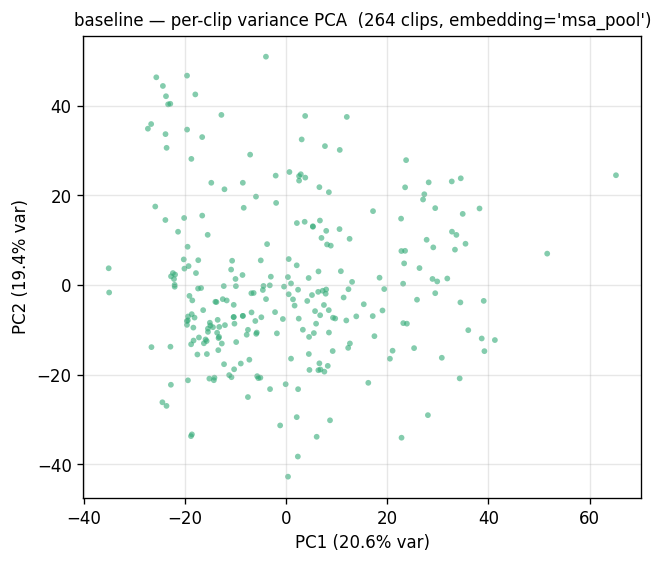

In [45]:
# §6.2 per-clip variance PCA
X, names, labels = extract_pair_embeddings(
    str(ckpt), test_sets[PRIMARY_EVAL],
    embedding="msa_pool",
)
PER_VARIANT_RESULTS[VARIANT]["embedding"] = {"X": X, "names": names, "labels": labels, "kind": "msa_pool"}

from sklearn.decomposition import PCA
pca = PCA(n_components=2, random_state=ENV["seed"]).fit(X)
xy  = pca.transform(X)
v1, v2 = pca.explained_variance_ratio_

fig, ax = plt.subplots(figsize=(6, 5), facecolor="white")
ax.scatter(xy[:, 0], xy[:, 1], s=12, alpha=0.6, c="#3a7", edgecolor="none")
ax.set_xlabel(f"PC1 ({v1*100:.1f}% var)")
ax.set_ylabel(f"PC2 ({v2*100:.1f}% var)")
ax.set_title(f"{VARIANT} — per-clip variance PCA  ({X.shape[0]} clips, embedding='msa_pool')", fontsize=10)
ax.grid(alpha=0.3)
show_and_save(fig, RESOURCES / f"figures/06_{VARIANT}_pca.png")


### §6.3 macro-MPJPE (per-family then macro-averaged)

Per-family MPJPE on A-eval, then equal-weight average over families with n≥10.
This neutralizes the walk-bias in AMASS labeled subset where ~half the clips
are walking.


In [46]:
# §6.3 macro-MPJPE on A-eval
recon = mpjpe_eval(str(ckpt), test_sets[PRIMARY_EVAL])
macro = macro_mpjpe(recon["mpjpe_per_family"], n_per_family=recon["n_per_family"], min_n=10)
PER_VARIANT_RESULTS[VARIANT]["mpjpe"] = {
    "overall":          float(recon["mpjpe_overall"]),
    "macro":            float(macro),
    "per_family":       recon["mpjpe_per_family"],
    "n_per_family":     recon["n_per_family"],
}

import pandas as pd
fam_df = pd.DataFrame({
    "mpjpe_m": pd.Series(recon["mpjpe_per_family"]),
    "n":       pd.Series(recon["n_per_family"]),
}).sort_values("n", ascending=False)
print(f"[{VARIANT}] overall MPJPE = {recon['mpjpe_overall']:.4f} m;   macro (min_n=10) = {macro:.4f} m")
fam_df


/home/arenalabs/miniconda3/envs/rot/lib/python3.12/site-packages/torch/nn/modules/transformer.py:392: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  warnings.warn(


[baseline] overall MPJPE = 0.0096 m;   macro (min_n=10) = 0.0094 m


,mpjpe_m,n
dance,0.011262,93
walk,0.009088,88
locomotion,0.007860,54
manipulate,0.009283,12
sit,0.009110,9
fight,0.009715,3
run,0.009515,2
gesture,0.006715,1
jump,0.008285,1
stretch,0.006200,1


### §6.4 modularity K-sweep (K=3,5,7,10)

KMeans modularity / silhouette / NMI vs ground-truth `action_label` over
K ∈ {3, 5, 7, 10}. Multi-K so the headline metric isn't K-cherry-picked.


[baseline] using MSA-pool embedding


/home/arenalabs/miniconda3/envs/rot/lib/python3.12/site-packages/torch/nn/modules/transformer.py:392: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  warnings.warn(


[baseline] no pair tensor; returning None


/home/arenalabs/miniconda3/envs/rot/lib/python3.12/site-packages/torch/nn/modules/transformer.py:392: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  warnings.warn(


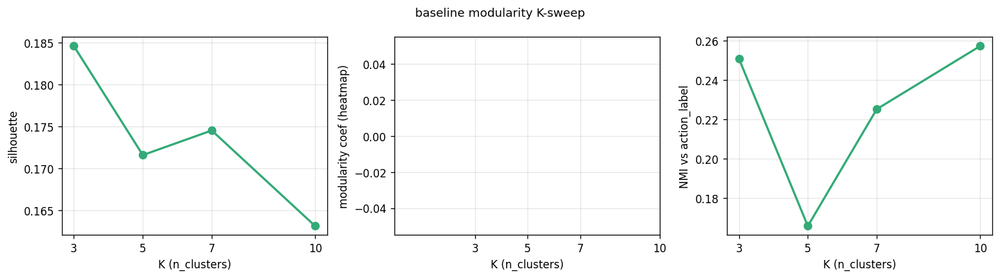

In [47]:
# §6.4 K-sweep over {3, 5, 7, 10}
ks = [3, 5, 7, 10]
ksweep = modularity_k_sweep(  # #3 new wrapper
    str(ckpt), test_sets[PRIMARY_EVAL],
    ks=ks, embedding="msa_pool", seed=ENV["seed"],
)
PER_VARIANT_RESULTS[VARIANT]["k_sweep"] = ksweep

# K-sweep plot (3 metrics × 4 K values, 1 line each)
fig = plot_modularity_k_sweep(ksweep, title=f"{VARIANT} modularity K-sweep")
show_and_save(fig, RESOURCES / f"figures/06_{VARIANT}_k_sweep.png")


### §6.5 `pair_variance` scalar

Single number summarizing per-clip variance — gives §9.2 thesis a numeric
headline. Reported in two flavors:
- `pair_norm`: variance over per-clip pair tensor norms (pair-bearing only)
- `msa_pool`: variance over per-clip MSA-pool embeddings (all 6 variants)


In [48]:
# §6.5 pair_variance scalar (both flavors when applicable)
flavors = ["msa_pool"] + (["pair_norm"] if VARIANT_CAPS[VARIANT]["use_pair"] else [])
pvar = {}
for flv in flavors:
    pvar[flv] = pair_variance_scalar(  # #10 new metric
        str(ckpt), test_sets[PRIMARY_EVAL],
        embedding=flv, seed=ENV["seed"],
    )
PER_VARIANT_RESULTS[VARIANT]["pair_variance"] = pvar
print(f"[{VARIANT}] pair_variance: {pvar}")


/home/arenalabs/miniconda3/envs/rot/lib/python3.12/site-packages/torch/nn/modules/transformer.py:392: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  warnings.warn(


[baseline] using MSA-pool embedding


[baseline] pair_variance: {'msa_pool': 3.137788442694609}


### §6.6 reconstruction GIFs (4 samples)

4 representative A-eval clips: GT mesh + this variant's reconstruction
(FM 1-step denoise from t=0.95 → un-normalize → FK → LBS → mesh GIF).


  ✓ GT  → gt.gif


/home/arenalabs/miniconda3/envs/rot/lib/python3.12/site-packages/torch/nn/modules/transformer.py:392: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  warnings.warn(


  ✓ baseline       → baseline.gif


  ✓ GT  → gt.gif


  ✓ baseline       → baseline.gif


  ✓ GT  → gt.gif


  ✓ baseline       → baseline.gif


  ✓ GT  → gt.gif


  ✓ baseline       → baseline.gif
--- 02_5_resources/figures/recon_gifs/baseline/sample_00_clip_3471/gt.gif ---


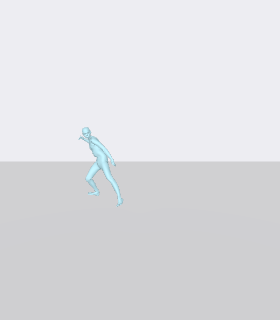

--- 02_5_resources/figures/recon_gifs/baseline/sample_00_clip_3471/baseline.gif ---


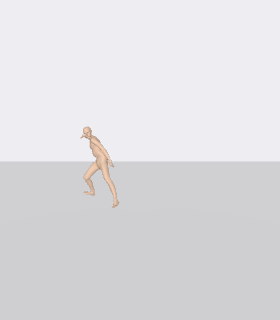

--- 02_5_resources/figures/recon_gifs/baseline/sample_01_clip_4121/gt.gif ---


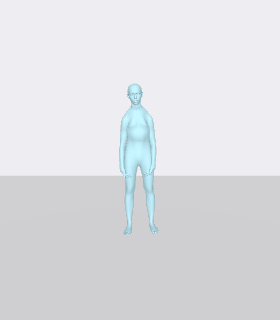

--- 02_5_resources/figures/recon_gifs/baseline/sample_01_clip_4121/baseline.gif ---


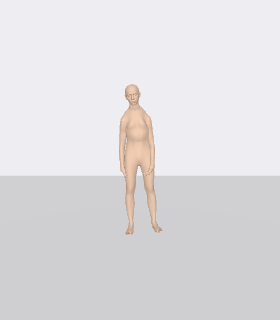

--- 02_5_resources/figures/recon_gifs/baseline/sample_02_clip_6146/gt.gif ---


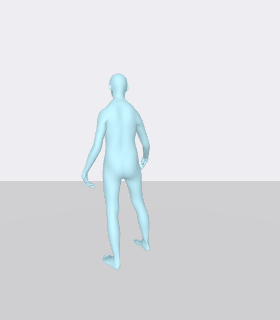

--- 02_5_resources/figures/recon_gifs/baseline/sample_02_clip_6146/baseline.gif ---


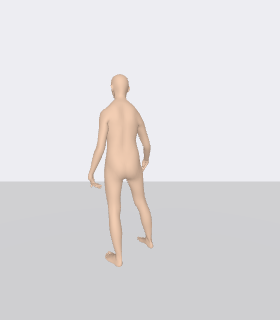

--- 02_5_resources/figures/recon_gifs/baseline/sample_03_clip_4466/gt.gif ---


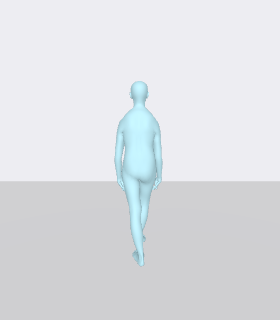

--- 02_5_resources/figures/recon_gifs/baseline/sample_03_clip_4466/baseline.gif ---


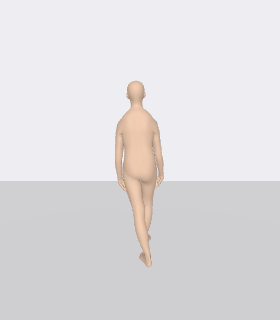

In [49]:
# §6.6 reconstruction GIFs — 4 samples, this variant only
ae = test_sets[PRIMARY_EVAL]
rng = np.random.default_rng(ENV["seed"])
sample_idxs = rng.choice(ae.indices, size=4, replace=False).tolist()

gif_dir = RESOURCES / f"figures/recon_gifs/{VARIANT}"
written_paths = []
for i, clip_idx in enumerate(sample_idxs):
    sub_dir = gif_dir / f"sample_{i:02d}_clip_{int(clip_idx)}"
    paths = render_recon_gif_all(
        int(clip_idx), sub_dir,
        ckpt_paths={VARIANT: ckpt},
        stride=3, fps=10, viewport=(280, 320),
    )
    written_paths.extend(paths)

PER_VARIANT_RESULTS[VARIANT]["gifs"] = [str(p) for p in written_paths]
for p in written_paths:
    print(f"--- {p} ---")
    display(Image(filename=str(p)))


## §7 Cross-variant comparison (figures only — no conclusions)

Side-by-side artifacts that are only meaningful across variants. Plots
generated; **interpretation deferred to joint review**.


### §7.1 4-way pair heatmap (pair-bearing variants)


variants in 4-way: ['full', 'opm_only', 'triangle_only', 'pair_static']


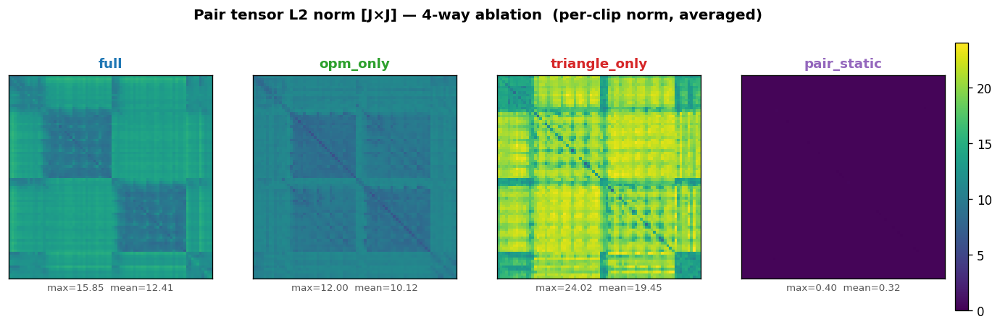

In [50]:
# §7.1 4-way pair heatmap — full / opm_only / triangle_only / pair_static
heatmaps = {v: PER_VARIANT_RESULTS[v]["pair_heatmap"]
            for v in ["full", "opm_only", "triangle_only", "pair_static"]
            if PER_VARIANT_RESULTS[v].get("pair_heatmap") is not None}
print(f"variants in 4-way: {list(heatmaps.keys())}")

fig = plot_pair_heatmap_4way(heatmaps)
show_and_save(fig, RESOURCES / "figures/07_pair_heatmap_4way.png")


### §7.2 6-way PCA on MSA-pool embeddings

Uses MSA-pool (not pair_norm) so axial_only and baseline can be included.


[full] using MSA-pool embedding


[opm_only] using MSA-pool embedding


[triangle_only] using MSA-pool embedding


[pair_static] using MSA-pool embedding


[axial_only] using MSA-pool embedding


/home/arenalabs/miniconda3/envs/rot/lib/python3.12/site-packages/torch/nn/modules/transformer.py:392: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  warnings.warn(


[baseline] using MSA-pool embedding


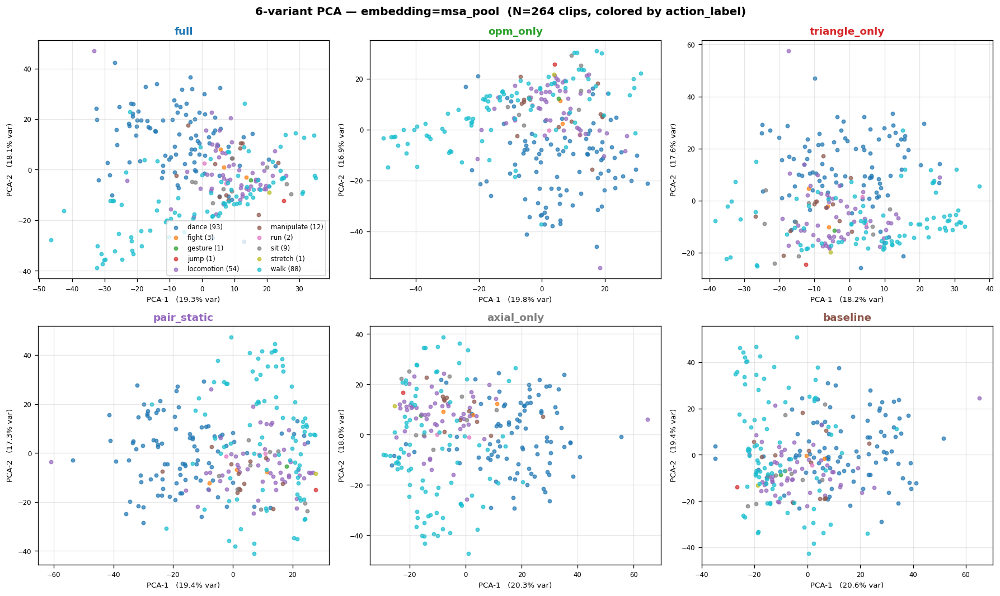

In [51]:
# §7.2 6-way PCA — MSA-pool embedding for all 6 variants
# plot_pca_6way takes (ckpts: dict, subset, ...) and runs extract_pair_embeddings internally
ckpts_all = {v: str(CKPT_ROOT / v / "latest.pt") for v in VARIANT_CAPS}

fig = plot_pca_6way(
    ckpts_all, test_sets[PRIMARY_EVAL],
    embedding="msa_pool",
    n_clips=300,
    seed=ENV["seed"],
)
show_and_save(fig, RESOURCES / "figures/07_pca_6way_msa_pool.png")


### §7.3 K-sweep modularity overlay (all variants on one plot)


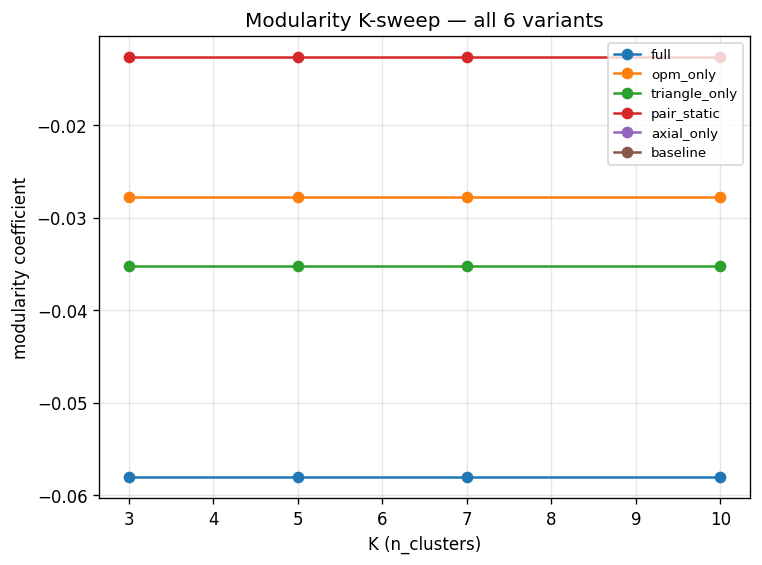

In [52]:
# §7.3 K-sweep overlay — one line per variant, x=K, y=modularity_coef
import pandas as pd
ksweep_overlay = {v: PER_VARIANT_RESULTS[v]["k_sweep"] for v in VARIANT_CAPS}

# TODO: dedicated plot_modularity_k_sweep_overlay() in viz_eval or eval_extras
fig, ax = plt.subplots(figsize=(7, 5), facecolor="white")
for v, ks in ksweep_overlay.items():
    xs = [r["k"] for r in ks]
    ys = [r.get("modularity_coef", float("nan")) for r in ks]
    ax.plot(xs, ys, marker="o", label=v)
ax.set_xlabel("K (n_clusters)")
ax.set_ylabel("modularity coefficient")
ax.set_title("Modularity K-sweep — all 6 variants")
ax.legend(fontsize=8)
ax.grid(alpha=0.3)
show_and_save(fig, RESOURCES / "figures/07_k_sweep_overlay.png")


### §7.4 macro-MPJPE bar chart (all 6 variants)


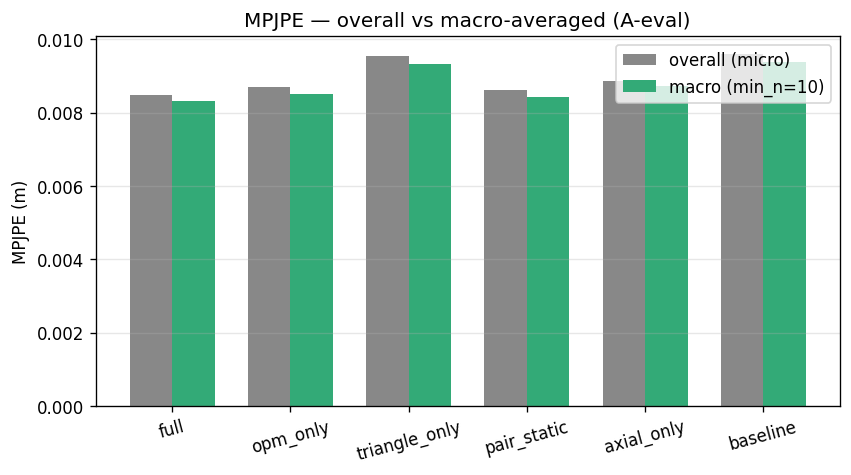

,overall,macro
full,0.008491,0.008310
opm_only,0.008688,0.008504
triangle_only,0.009552,0.009323
pair_static,0.008622,0.008418
axial_only,0.008871,0.008720
baseline,0.009600,0.009373


In [53]:
# §7.4 macro-MPJPE bar chart
import pandas as pd
mpjpe_df = pd.DataFrame({
    v: {"overall": PER_VARIANT_RESULTS[v]["mpjpe"]["overall"],
        "macro":   PER_VARIANT_RESULTS[v]["mpjpe"]["macro"]}
    for v in VARIANT_CAPS
}).T

fig, ax = plt.subplots(figsize=(8, 4), facecolor="white")
x = np.arange(len(mpjpe_df))
ax.bar(x - 0.18, mpjpe_df["overall"], width=0.36, label="overall (micro)", color="#888")
ax.bar(x + 0.18, mpjpe_df["macro"],   width=0.36, label="macro (min_n=10)", color="#3a7")
ax.set_xticks(x); ax.set_xticklabels(mpjpe_df.index, rotation=15)
ax.set_ylabel("MPJPE (m)")
ax.set_title("MPJPE — overall vs macro-averaged (A-eval)")
ax.legend()
ax.grid(axis="y", alpha=0.3)
show_and_save(fig, RESOURCES / "figures/07_macro_mpjpe.png")
mpjpe_df


### §7.5 pair_variance scalar table


In [54]:
# §7.5 pair_variance summary table
import pandas as pd
pvar_df = pd.DataFrame({
    v: PER_VARIANT_RESULTS[v]["pair_variance"]
    for v in VARIANT_CAPS
}).T
print("pair_variance scalar (log10 by default — see eval_extras.pair_variance_scalar):")
pvar_df


pair_variance scalar (log10 by default — see eval_extras.pair_variance_scalar):


,msa_pool,pair_norm
full,3.056875,3.918322
opm_only,3.105063,3.557534
triangle_only,3.021757,-5.313394
pair_static,3.147769,-8.835344
axial_only,3.136166,NaN
baseline,3.137788,NaN


## §8 Headline numbers dump

Single JSON consolidating §1-§7 numbers; consumed by paper draft scripts.
**No interpretation here** — just structured numbers.


In [55]:
# §8 Dump headline_numbers_v2.json
import json

HEADLINE_V2 = {
    "regime": "fm_v1_30k_headline",
    "n_steps": 30000,
    "primary_eval": PRIMARY_EVAL,
    "per_variant": {
        v: {
            "mpjpe_overall":  PER_VARIANT_RESULTS[v]["mpjpe"]["overall"],
            "mpjpe_macro":    PER_VARIANT_RESULTS[v]["mpjpe"]["macro"],
            "pair_variance":  PER_VARIANT_RESULTS[v]["pair_variance"],
            "k_sweep":        PER_VARIANT_RESULTS[v]["k_sweep"],
        }
        for v in VARIANT_CAPS
    }
}
out = RESOURCES / "headline_numbers_v2.json"
out.write_text(json.dumps(HEADLINE_V2, indent=2, default=float))
print(f"wrote {out}  ({out.stat().st_size} bytes)")


wrote 02_5_resources/headline_numbers_v2.json  (11043 bytes)


## §9 Insights

**TODO: discuss with Lucas after running.**

Per-section observations and cross-variant patterns to be filled in
collaboratively after reviewing all figures and numbers from §1-§8.
